## Project 1: Insurance Claims Charges Prediction

In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter(action='ignore')

In [81]:
#Read the Data
data = pd.read_csv('insurance.csv')

In [82]:
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [83]:
data.shape

(1338, 7)

In [84]:
data.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [85]:
np.sum(data.duplicated())

np.int64(1)

In [86]:
data.drop_duplicates(inplace=True)
np.sum(data.duplicated())

np.int64(0)

In [87]:
data.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


In [88]:
# dataset information
data.info()

<class 'pandas.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1337 non-null   int64  
 1   sex       1337 non-null   str    
 2   bmi       1337 non-null   float64
 3   children  1337 non-null   int64  
 4   smoker    1337 non-null   str    
 5   region    1337 non-null   str    
 6   charges   1337 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 105.2 KB


## EDA

### Univariate Analysis

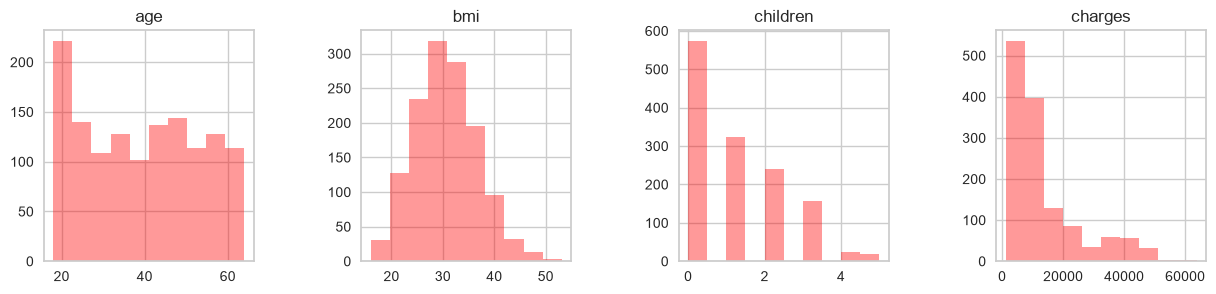

In [89]:
# Drawing Histogram plots for numeric variables to understand their distribution

Numeric_features = [0, 2, 3, 6]

plt.figure(figsize = (15, 3))
plt.subplots_adjust(hspace = 0.5, wspace = 0.51)

for i in range(1, len(Numeric_features)+1):
    plt.subplot(1, 4, i)
    plt.hist(x = data.iloc[: , Numeric_features[i - 1]], alpha = 0.4, color = 'red')
    plt.title(data.columns[Numeric_features[i - 1]])
plt.show()

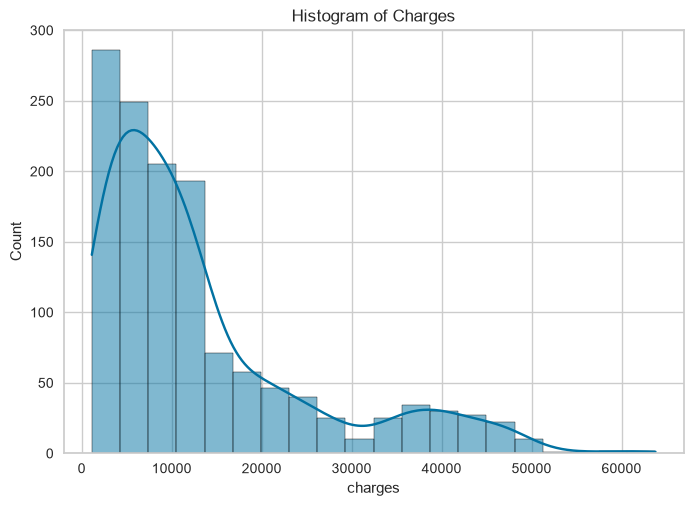

In [90]:
# Histogram
sns.histplot(data['charges'], bins=20, kde=True)
plt.title('Histogram of Charges')
plt.show()

In [91]:
data['smoker'].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [92]:
data['sex'].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

In [93]:
data['region'].value_counts()

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

In [94]:
data.groupby(by='sex')['charges'].mean()

sex
female    12569.578844
male      13974.998864
Name: charges, dtype: float64

In [95]:
data.groupby(by='region')['charges'].mean()

region
northeast    13406.384516
northwest    12450.840844
southeast    14735.411438
southwest    12346.937377
Name: charges, dtype: float64

In [96]:
data.groupby(by='smoker')['charges'].mean()

smoker
no      8440.660307
yes    32050.231832
Name: charges, dtype: float64

In [97]:
data.groupby(by='smoker')['age'].mean()

smoker
no     39.404516
yes    38.514599
Name: age, dtype: float64

In [98]:
data.groupby(by=['sex','smoker'])['age'].mean().unstack()

smoker,no,yes
sex,,
female,39.691042,38.608696
male,39.100775,38.446541


In [99]:
data.groupby(by=['sex','smoker'])['charges'].mean().unstack()

smoker,no,yes
sex,,
female,8762.297300,30678.996276
male,8099.700161,33042.005975


In [100]:
data.groupby(by=['region','sex'])['charges'].mean().unstack()

sex,female,male
region,,
northeast,12953.203151,13854.005374
northwest,12479.870397,12421.085553
southeast,13499.669243,15879.617173
southwest,11274.411264,13412.883576


In [101]:
data.groupby(by='children')['age'].mean()

children
0    38.478185
1    39.453704
2    39.445833
3    41.566879
4    39.000000
5    35.611111
Name: age, dtype: float64

In [102]:
data[data['children']>4]

,age,sex,bmi,children,smoker,region,charges
32,19,female,28.600,5,no,southwest,4687.79700
71,31,male,28.500,5,no,northeast,6799.45800
166,20,female,37.000,5,no,southwest,4830.63000
413,25,male,23.900,5,no,southwest,5080.09600
425,45,male,24.310,5,no,southeast,9788.86590
438,52,female,46.750,5,no,southeast,12592.53450
568,49,female,31.900,5,no,southwest,11552.90400
640,33,male,42.400,5,no,southwest,6666.24300
877,33,male,33.440,5,no,southeast,6653.78860
932,46,male,25.800,5,no,southwest,10096.97000


In [103]:
data[(data['children']>4) & (data['smoker']=='yes')]

,age,sex,bmi,children,smoker,region,charges
1085,39,female,18.3,5,yes,southwest,19023.26


In [104]:
data[(data['bmi']>40) & (data['smoker']=='yes')]

,age,sex,bmi,children,smoker,region,charges
14,27,male,42.130,0,yes,southeast,39611.75770
185,36,male,41.895,3,yes,northeast,43753.33705
265,46,male,42.350,3,yes,southeast,46151.12450
281,54,male,40.565,3,yes,northeast,48549.17835
292,25,male,45.540,2,yes,southeast,42112.23560
377,24,male,40.150,0,yes,southeast,38126.24650
530,57,male,42.130,1,yes,southeast,48675.51770
543,54,female,47.410,0,yes,southeast,63770.42801
549,43,female,46.200,0,yes,southeast,45863.20500
569,48,male,40.565,2,yes,northwest,45702.02235


In [105]:
data[(data['bmi']>40) & (data['smoker']=='yes')]['charges'].mean()

np.float64(45467.786145714286)

In [106]:
data[(data['bmi']<=40) & (data['smoker']=='yes')]['charges'].mean()

np.float64(30936.521789644266)

In [107]:
data[(data['bmi']>40) & (data['smoker']=='no')]['charges'].mean()

np.float64(8179.664366714287)

In [108]:
data[(data['bmi']<=40) & (data['smoker']=='no')]['charges'].mean()

np.float64(8459.058811831823)

In [109]:
data[data['bmi']>40]['age'].mean()

np.float64(40.582417582417584)

In [110]:
data[data['smoker']=='yes']['age'].mean()

np.float64(38.51459854014598)

In [111]:
data[data['smoker']=='no']['age'].mean()

np.float64(39.404515522107246)

### Bivariate analysis

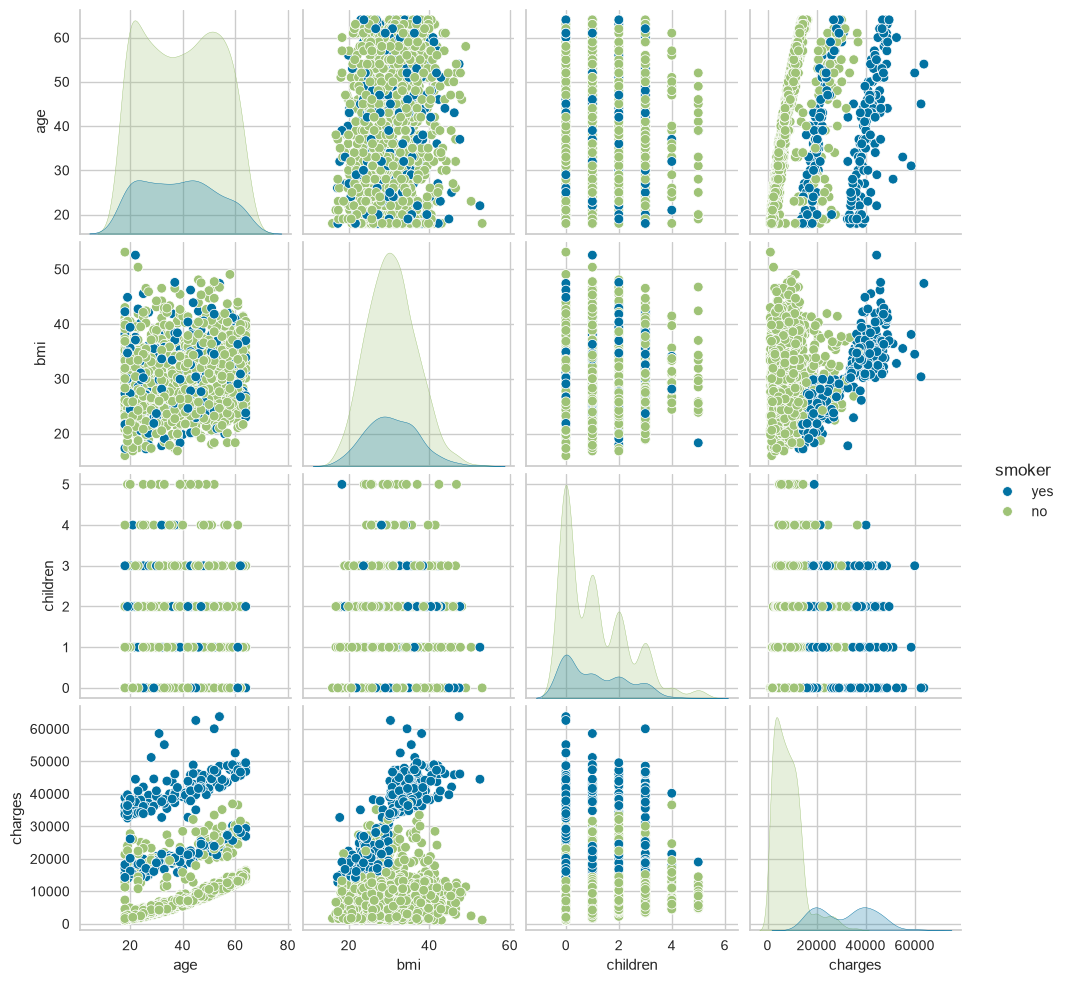

In [112]:
sns.pairplot(data,hue='smoker')
plt.show()

In [113]:
#Correlation analysis
round(data.iloc[:, Numeric_features].corr(), 2)

,age,bmi,children,charges
age,1.00,0.11,0.04,0.30
bmi,0.11,1.00,0.01,0.20
children,0.04,0.01,1.00,0.07
charges,0.30,0.20,0.07,1.00


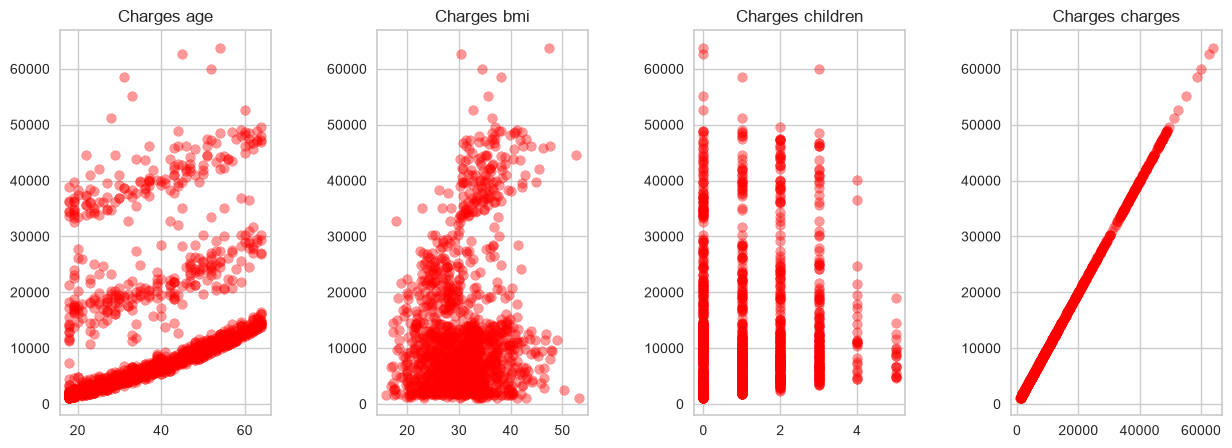

In [114]:
#Scatter plot

plt.figure(figsize = (15, 5))
plt.subplots_adjust(hspace = 0.5, wspace = 0.5)

for i in range(1, len(Numeric_features)+1):
    plt.subplot(1, 4, i)
    plt.scatter(x = data.iloc[: , Numeric_features[i - 1]], y = data['charges'], alpha = 0.4, color = 'red')
    plt.title('Charges ' + data.columns[Numeric_features[i - 1]])
plt.show()

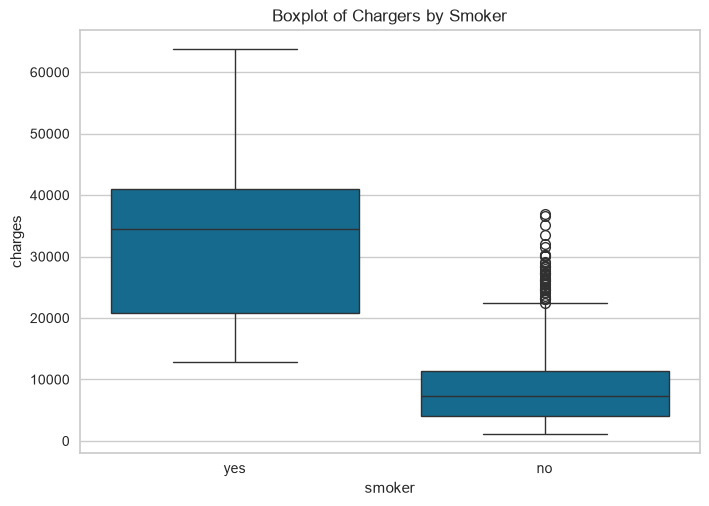

In [115]:
# Boxplot
sns.boxplot(x='smoker', y='charges', data=data)
plt.title('Boxplot of Chargers by Smoker')
plt.show()

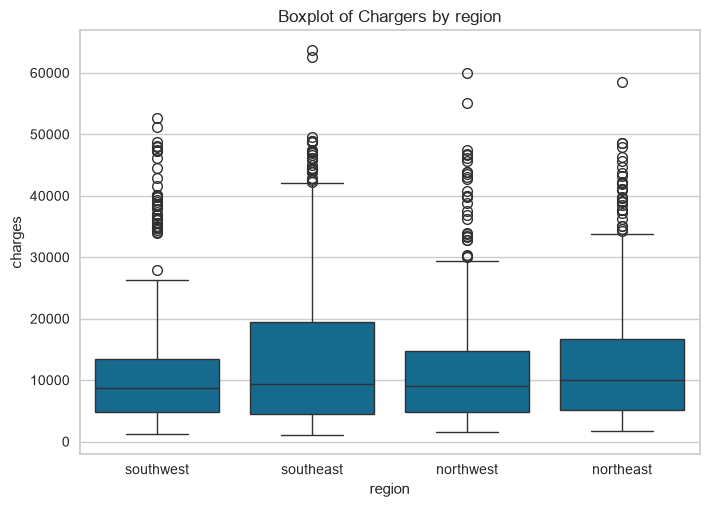

In [116]:
# Boxplot
sns.boxplot(x='region', y='charges', data=data)
plt.title('Boxplot of Chargers by region')
plt.show()

Text(0.5, 1.0, 'region vs charges')

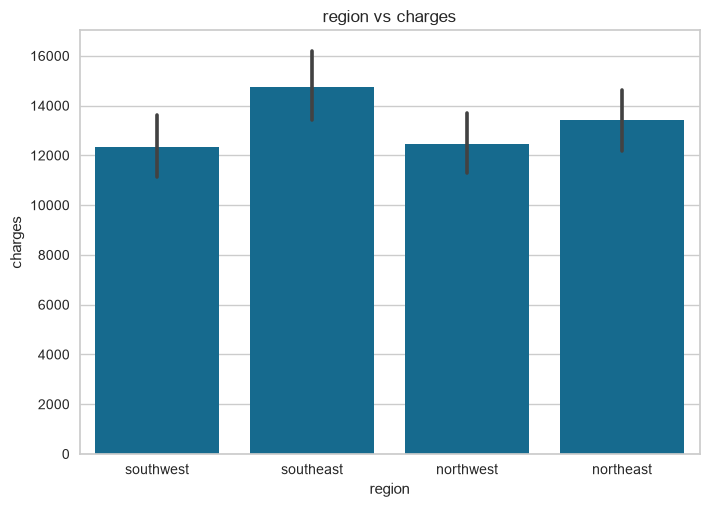

In [117]:
# region vs charges
# region actually does not play any role in determining the insurance charges
sns.barplot(x = 'region', y = 'charges', data = data)
plt.title('region vs charges')

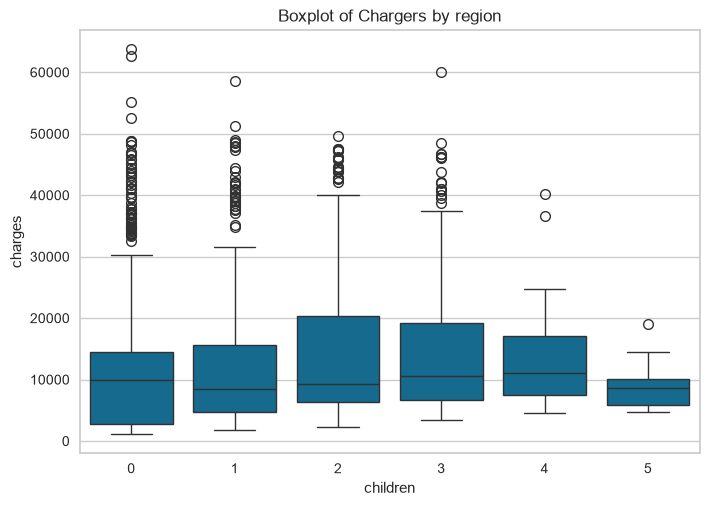

In [118]:
# Boxplot
sns.boxplot(x='children', y='charges', data=data)
plt.title('Boxplot of Chargers by region')
plt.show()

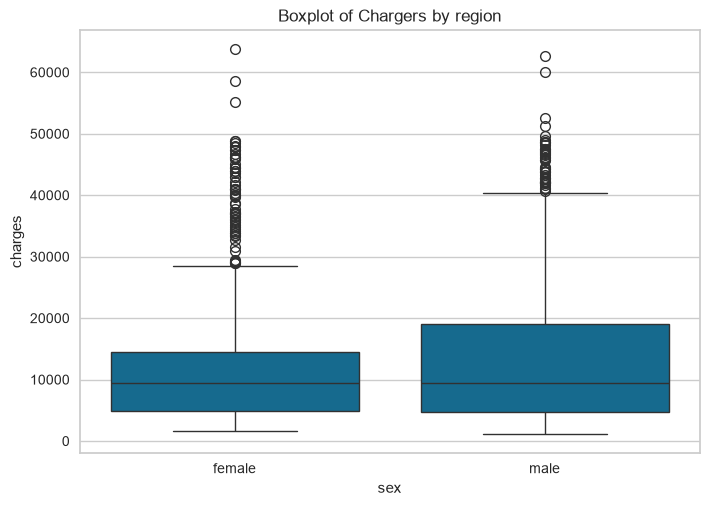

In [119]:
# Boxplot
sns.boxplot(x='sex', y='charges', data=data)
plt.title('Boxplot of Chargers by region')
plt.show()

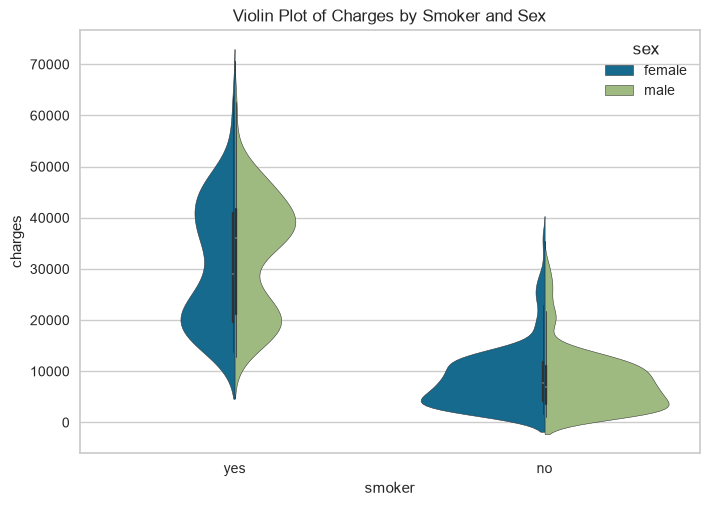

In [120]:
# Violin plot
sns.violinplot(x='smoker', y='charges', data=data, hue='sex', split=True)
plt.title('Violin Plot of Charges by Smoker and Sex')
plt.show()

In [121]:
data[data['charges']<0]

,age,sex,bmi,children,smoker,region,charges


Text(0.5, 1.0, 'Age vs Charges')

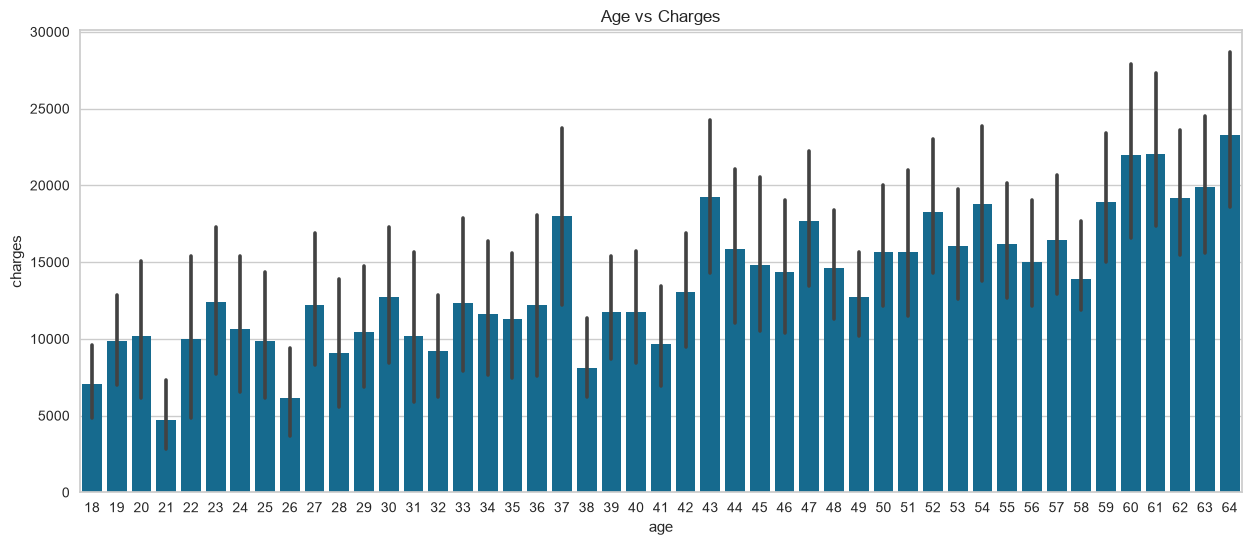

In [122]:
# Age vs Charges
# the more the age the more will be insurance charge

plt.figure(figsize = (15, 6))
sns.barplot(x = 'age', y = 'charges', data = data)

plt.title("Age vs Charges")

### Outlier Detection

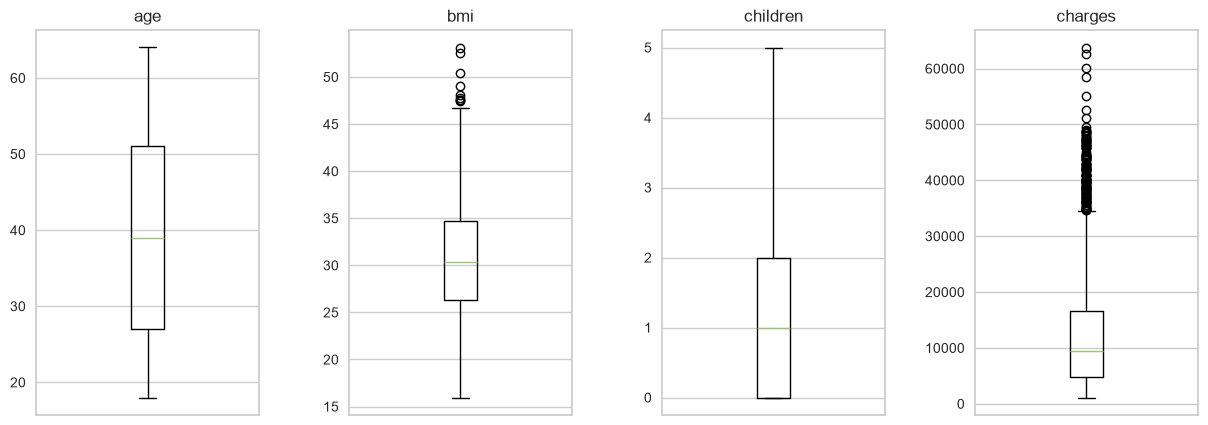

In [123]:
#Boxplot of numeric variables
import matplotlib.pyplot as plt

plt.figure(figsize = (15, 5))
plt.subplots_adjust(hspace = 0.4, wspace = 0.4)

for i in range(1, len(Numeric_features)+1):
    plt.subplot(1, 4, i)
    plt.boxplot(data.iloc[: , Numeric_features[i - 1]])
    plt.xticks([]) #remove the xticks 
    plt.title(data.columns[Numeric_features[i - 1]])
plt.show()

In [124]:
def Outlier_Removal(data, column):
    # Make a copy of the data to avoid modifying the original
    df = data.copy()
    
    # Reset the index to ensure continuous indexing
    df = df.reset_index(drop=True)
    
    # Calculate Q1, Q3 and IQR
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    
    # Define bounds for outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Filter out outliers
    df_filtered = df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]
    
    # Reset index again after filtering
    df_filtered = df_filtered.reset_index(drop=True)
    
    return df_filtered

In [125]:
print("Old Shape: ", data.shape)

Old Shape:  (1337, 7)


In [126]:
Data_cleaned = Outlier_Removal(data, 'bmi')
Data_cleaned.shape

(1328, 7)

## Data Preparing

In [127]:
X = Data_cleaned.drop('charges',axis=1)
X.head()

,age,sex,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest


In [128]:
y = Data_cleaned['charges']
y.head()

0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64

In [129]:
X = pd.get_dummies(data=X, drop_first=True)
X.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,False,True,False,False,True
1,18,33.770,1,True,False,False,True,False
2,28,33.000,3,True,False,False,True,False
3,33,22.705,0,True,False,True,False,False
4,32,28.880,0,True,False,True,False,False


### Train - Test Split

In [130]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=40)

print('Train data shape = ', X_train.shape)
print('Test data shape = ', X_test.shape)

Train data shape =  (929, 8)
Test data shape =  (399, 8)


## Models Building

### Linear Regression

In [131]:
# Scaling data

from sklearn.preprocessing import StandardScaler

Scaler = StandardScaler()
X_train_scaled = Scaler.fit_transform(X_train)
X_test_scaled = Scaler.transform(X_test)

In [132]:
#Feature selection

from sklearn.feature_selection import RFECV
from sklearn.linear_model import LinearRegression

FeatureSelector = RFECV(LinearRegression(), cv = 10, scoring = 'neg_root_mean_squared_error')
FeatureSelector.fit(X_train_scaled, y_train)

#FeatureSelector.support_
#Selected features indices
Selected_features = np.where(FeatureSelector.support_)
Selected_features

(array([0, 1, 2, 4, 6]),)

In [133]:
# Model 1: Linear regression for selected features

Model_1 = LinearRegression()

# Fit the model on train data
Model_1.fit(X_train_scaled[:, Selected_features[0]], y_train)

# Coefficients ?
print('Coefficients: ',Model_1.coef_)
print('Intercept: ',Model_1.intercept_)

Coefficients:  [3431.46797429 2033.47828752  539.3067009  9606.41371084 -433.12098826]
Intercept:  13261.209761968781


In [134]:
X_train_scaled.shape

(929, 8)

In [135]:
# Predict the response (Price) for train data
from sklearn import metrics

y_train_prediction_1 = Model_1.predict(X_train_scaled[:, Selected_features[0]])

print('MAE Train: ', metrics.mean_absolute_error(y_train, y_train_prediction_1))
print('MSE Train: ', metrics.mean_squared_error(y_train, y_train_prediction_1))
print('RMSE Train: ', np.sqrt(metrics.mean_squared_error(y_train, y_train_prediction_1)))
print('MAPE Train: ', metrics.mean_absolute_percentage_error(y_train, y_train_prediction_1))
print('R^2 Train: ', metrics.r2_score(y_train, y_train_prediction_1))

MAE Train:  4174.600460077426
MSE Train:  36366702.651052035
RMSE Train:  6030.481129317298
MAPE Train:  0.42515141324211037
R^2 Train:  0.7502549953504094


In [136]:
# Predict the response for test data
y_test_prediction_1 = Model_1.predict(X_test_scaled[:, Selected_features[0]])

Results = pd.DataFrame({'MSE': metrics.mean_squared_error(y_test, y_test_prediction_1),
                        'RMSE': np.sqrt(metrics.mean_squared_error(y_test, y_test_prediction_1)),
                        'MAPE': metrics.mean_absolute_percentage_error(y_test, y_test_prediction_1) * 100,
                        'MAE' : metrics.mean_absolute_error(y_test, y_test_prediction_1),
                        'R^2' : metrics.r2_score(y_test, y_test_prediction_1)},                         
                       index = ['LR - Selected Features'])
Results

,MSE,RMSE,MAPE,MAE,R^2
LR - Selected Features,3.570983e+07,5975.76999,41.937878,4137.698443,0.744327


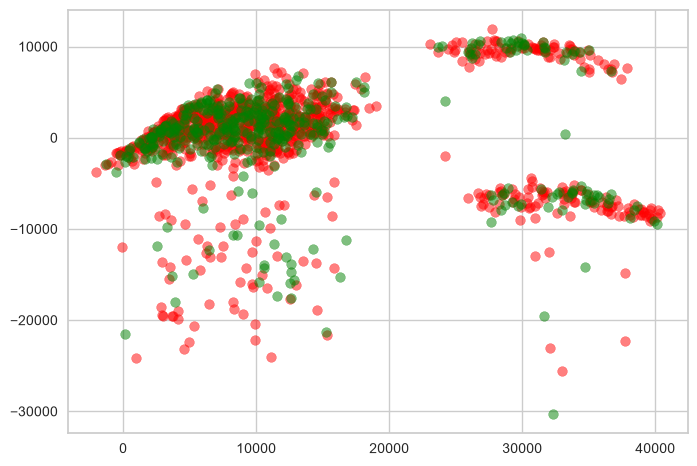

In [140]:
# Another way to show residual plots
Residual_train =  y_train_prediction_1 - y_train
Residual_test =  y_test_prediction_1 - y_test

plt.scatter(y_train_prediction_1,Residual_train,c='red',alpha=0.5)
plt.scatter(y_test_prediction_1,Residual_test,c='green',alpha=0.5)
plt.show()

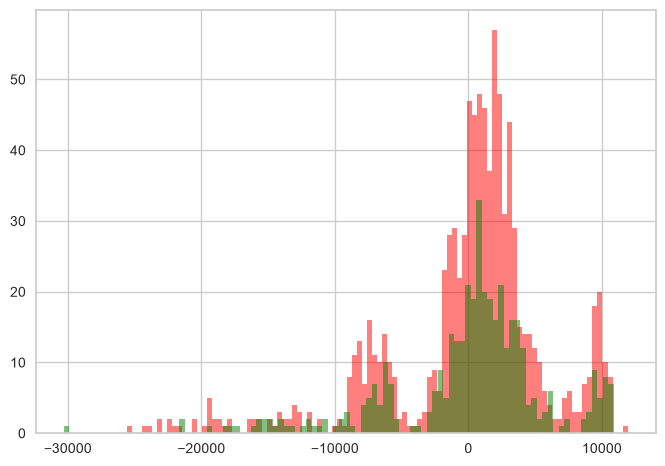

In [141]:
# Another way to show residual plots
plt.hist(Residual_train,bins=100,color='red',alpha=0.5)
plt.hist(Residual_test,bins=100,color='green',alpha=0.5)
plt.show()

In [142]:
#Box-Cox transformation
from sklearn.preprocessing import PowerTransformer
boxcox = PowerTransformer(method = 'box-cox')
boxcox.fit(y_train.values.reshape(-1, 1))
boxcox.lambdas_

array([0.05024669])

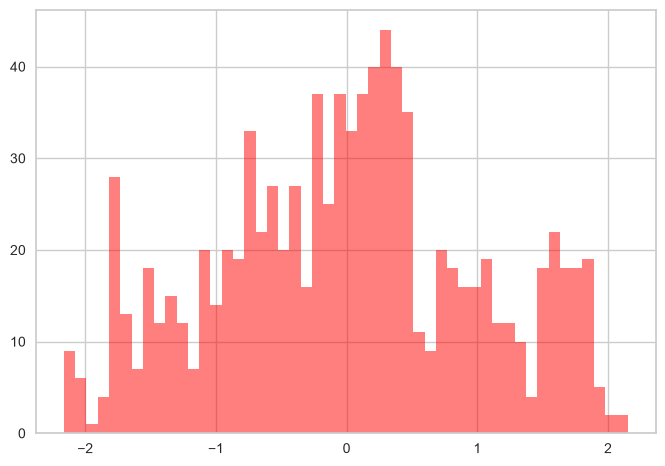

In [143]:
trans_y_train = boxcox.fit_transform(y_train.values.reshape(-1, 1))
trans_y_test = boxcox.transform(y_test.values.reshape(-1, 1))
plt.hist(trans_y_train, color = 'red', alpha = 0.5, bins = 50)
plt.show()

In [144]:
# Model 3: Linear regression for selected features and Box Cox transformation

Model_2 = LinearRegression()

# Fit the model on train data
Model_2.fit(X_train_scaled[:, Selected_features[0]], trans_y_train)

# Coefficients ?
print('Coefficients: ',Model_2.coef_)
print('Intercept: ',Model_2.intercept_)

Coefficients:  [[ 0.50152251  0.09248212  0.12162447  0.68670053 -0.05652568]]
Intercept:  [8.4796794e-16]


In [145]:
y_train_prediction_2 = Model_2.predict(X_train_scaled[:, Selected_features[0]])

y_train_prediction_2 = pd.Series(boxcox.inverse_transform(y_train_prediction_2.reshape(-1, 1)).reshape(-1))

print('MAE Train: ', metrics.mean_absolute_error(y_train, y_train_prediction_2))
print('MSE Train: ', metrics.mean_squared_error(y_train, y_train_prediction_2))
print('RMSE Train: ', np.sqrt(metrics.mean_squared_error(y_train, y_train_prediction_2)))
print('MAPE Train: ', metrics.mean_absolute_percentage_error(y_train, y_train_prediction_2))
print('R^2 Train: ', metrics.r2_score(y_train, y_train_prediction_2))

MAE Train:  4018.792069824955
MSE Train:  57899364.81146603
RMSE Train:  7609.163213617252
MAPE Train:  0.2794025429497299
R^2 Train:  0.6023814071680866


In [146]:
#Predict the response in the test - model 2
y_test_prediction_2 = Model_2.predict(X_test_scaled[:, Selected_features[0]])
#Inverse transformation of predicted values
y_test_prediction_2 = pd.Series(boxcox.inverse_transform(y_test_prediction_2.reshape(-1, 1)).reshape(-1))


Results = pd.concat([Results, 
                             pd.DataFrame({'MSE': metrics.mean_squared_error(y_test, y_test_prediction_2),
                                          'RMSE': np.sqrt(metrics.mean_squared_error(y_test, y_test_prediction_2)),
                                          'MAPE': metrics.mean_absolute_percentage_error(y_test, y_test_prediction_2) * 100,
                                          'MAE' : metrics.mean_absolute_error(y_test, y_test_prediction_2),
                                          'R^2' : metrics.r2_score(y_test, y_test_prediction_2)},                         
                                           index = ['LR - Selected Feature - Box Cox'])])
Results


,MSE,RMSE,MAPE,MAE,R^2
LR - Selected Features,3.570983e+07,5975.769990,41.937878,4137.698443,0.744327
LR - Selected Feature - Box Cox,5.221271e+07,7225.836528,26.387955,3835.371101,0.626170


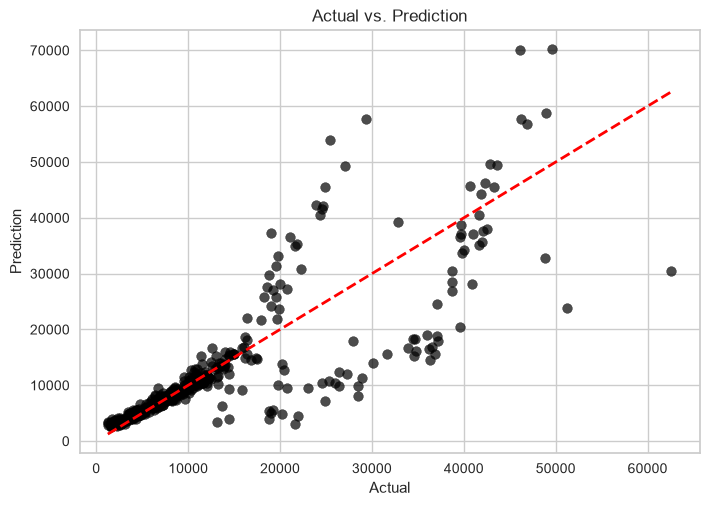

In [147]:
#Plot actual vs. prediction - Test
plt.scatter(y_test, y_test_prediction_2, c = 'black', alpha = 0.7)
plt.xlabel('Actual')
plt.ylabel('Prediction')
plt.title('Actual vs. Prediction')
xp = np.linspace(y_test.min() - 0.2, y_test.max() + 0.2, 100)
plt.plot(xp, xp, c = 'red', linewidth = 2, linestyle='--')
plt.show()

### KNN

In [149]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_neighbors': list(range(1, 100, 2)),  
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

knn = KNeighborsRegressor()

grid1 = GridSearchCV(knn, param_grid, cv=10)
grid1.fit(X_train_scaled, y_train)
grid1.best_params_

{'metric': 'euclidean', 'n_neighbors': 11, 'weights': 'distance'}

In [150]:
Model_3 = KNeighborsRegressor(n_neighbors=grid1.best_params_['n_neighbors'],
                              metric=grid1.best_params_['metric'],
                              weights=grid1.best_params_['weights'])

Model_3.fit(X_train_scaled, y_train)

y_train_prediction_3 = Model_3.predict(X_train_scaled)

print('MAE Train: ', metrics.mean_absolute_error(y_train, y_train_prediction_3))
print('MSE Train: ', metrics.mean_squared_error(y_train, y_train_prediction_3))
print('RMSE Train: ', np.sqrt(metrics.mean_squared_error(y_train, y_train_prediction_3)))
print('MAPE Train: ', metrics.mean_absolute_percentage_error(y_train, y_train_prediction_3))
print('R^2 Train: ', metrics.r2_score(y_train, y_train_prediction_3))

MAE Train:  13.456637836383207
MSE Train:  84112.17181377496
RMSE Train:  290.0209851265507
MAPE Train:  0.00459926642499612
R^2 Train:  0.9994223673522925


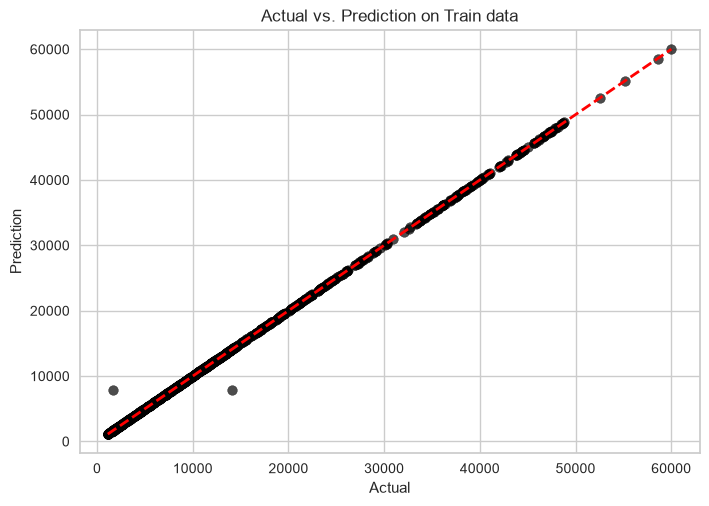

In [151]:
#Plot actual vs. prediction - Train
plt.scatter(y_train, y_train_prediction_3, c = 'black', alpha = 0.7)
plt.xlabel('Actual')
plt.ylabel('Prediction')
plt.title('Actual vs. Prediction on Train data')
xp = np.linspace(y_train.min() - 0.2, y_train.max() + 0.2, 100)
plt.plot(xp, xp, c = 'red', linewidth = 2, linestyle='--')
plt.show()

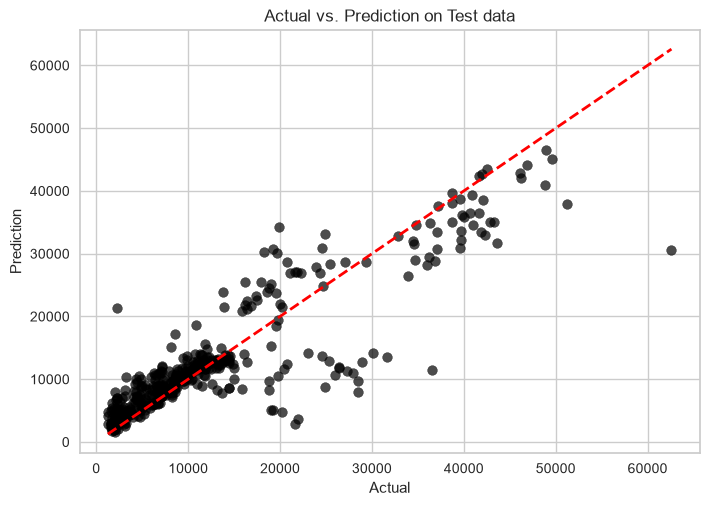

In [152]:
#Plot actual vs. prediction - Test
y_test_prediction_3 = Model_3.predict(X_test_scaled)

plt.scatter(y_test, y_test_prediction_3, c = 'black', alpha = 0.7)
plt.xlabel('Actual')
plt.ylabel('Prediction')
plt.title('Actual vs. Prediction on Test data')
xp = np.linspace(y_test.min() - 0.2, y_test.max() + 0.2, 100)
plt.plot(xp, xp, c = 'red', linewidth = 2, linestyle='--')
plt.show()

In [153]:
Results = pd.concat([Results, 
                             pd.DataFrame({'MSE': metrics.mean_squared_error(y_test, y_test_prediction_3),
                                           'RMSE': np.sqrt(metrics.mean_squared_error(y_test, y_test_prediction_3)),
                                           'MAPE': metrics.mean_absolute_percentage_error(y_test, y_test_prediction_3) * 100,
                                           'MAE' : metrics.mean_absolute_error(y_test, y_test_prediction_3),
                                           'R^2' : metrics.r2_score(y_test, y_test_prediction_3)},                         
                                           index = ['KNN - Tunned'])])
Results

,MSE,RMSE,MAPE,MAE,R^2
LR - Selected Features,3.570983e+07,5975.769990,41.937878,4137.698443,0.744327
LR - Selected Feature - Box Cox,5.221271e+07,7225.836528,26.387955,3835.371101,0.626170
KNN - Tunned,2.966151e+07,5446.238346,38.428636,3364.491897,0.787631


### Decision Tree

In [154]:
from sklearn.tree import DecisionTreeRegressor

param_grid={
    'splitter':['best', 'random'],
    'max_depth':range(2,7),
    'max_features':['auto', 'sqrt', 'log2'],
    'min_samples_leaf': range(2,30)
}

grid2=GridSearchCV(DecisionTreeRegressor(),param_grid,cv=10)
grid2.fit(X_train,y_train)
grid2.best_params_

{'max_depth': 6,
 'max_features': 'log2',
 'min_samples_leaf': 3,
 'splitter': 'best'}

In [155]:
Model_4 = DecisionTreeRegressor(max_depth=grid2.best_params_['max_depth'],
                                max_features=grid2.best_params_['max_features'],
                                min_samples_leaf=grid2.best_params_['min_samples_leaf'],
                                splitter=grid2.best_params_['splitter'],
                                random_state=123)

# Fit data to the training set
Model_4.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",6
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'log2'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",123
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes 

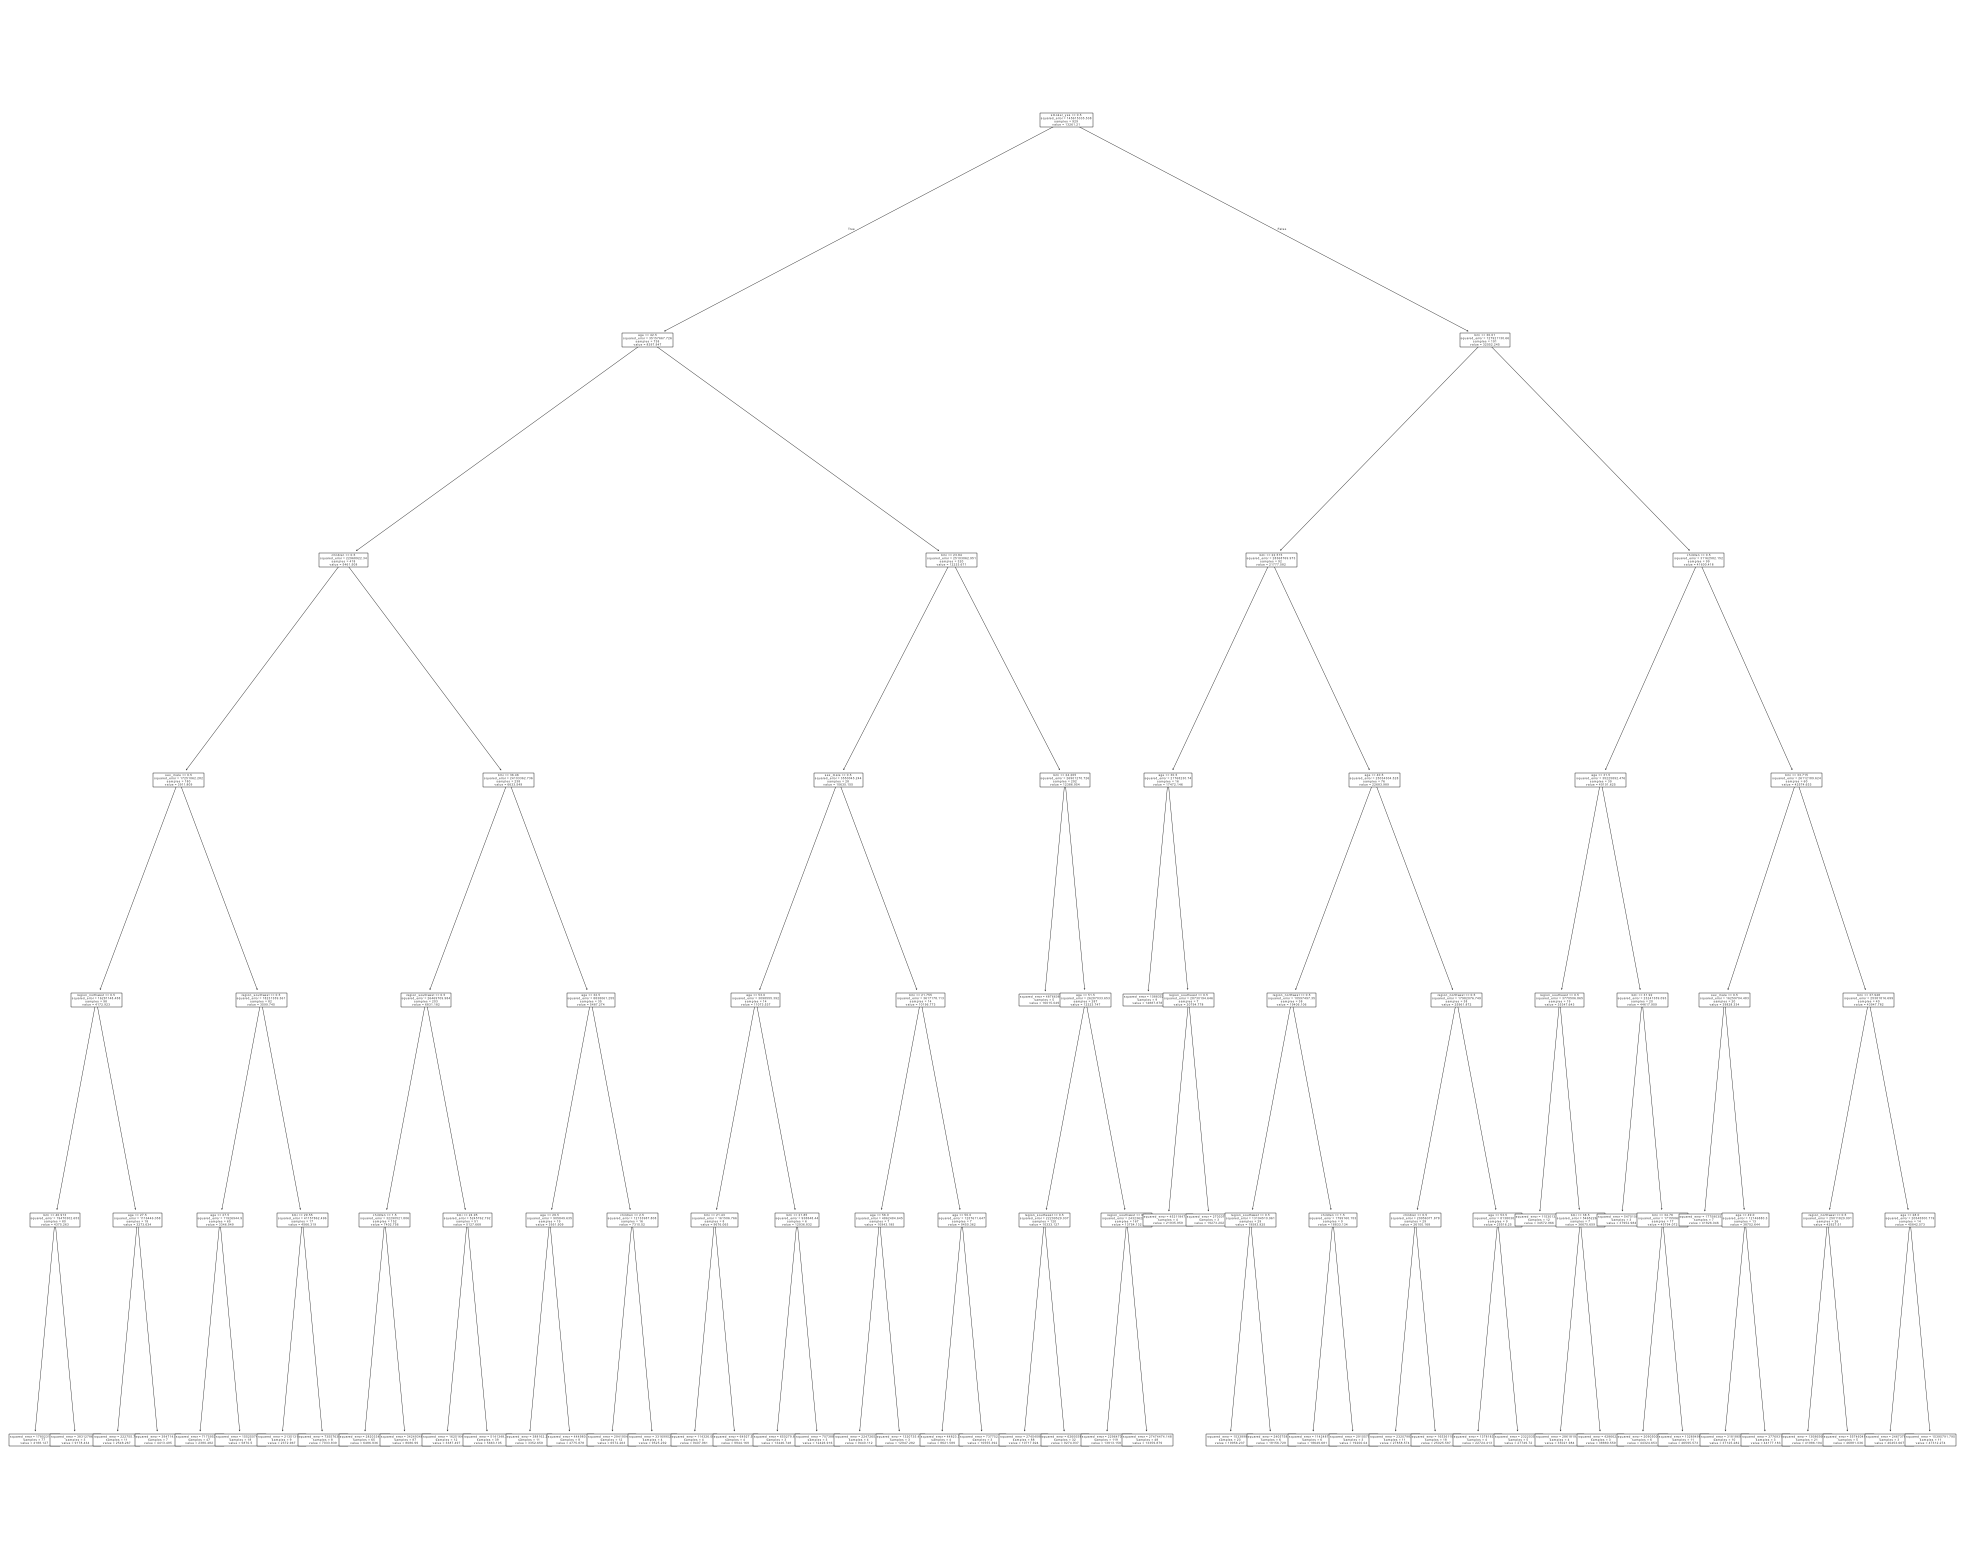

In [156]:
from sklearn.tree import plot_tree
plt.figure(figsize = (25, 20))
plot_tree(Model_4, feature_names = X_train.columns)
plt.show()

In [157]:
path=Model_4.cost_complexity_pruning_path(X_train,y_train)
alpha_grid=path['ccp_alphas']
alpha_grid

array([0.00000000e+00, 6.18987520e+02, 6.52089297e+02, 1.67931718e+03,
       6.90067802e+03, 1.00985082e+04, 1.03773624e+04, 1.12705325e+04,
       1.30837047e+04, 1.55467949e+04, 1.60201413e+04, 2.15517768e+04,
       2.25164846e+04, 2.42573732e+04, 2.81605415e+04, 4.06380212e+04,
       4.82993612e+04, 5.11510719e+04, 5.25969243e+04, 7.67600163e+04,
       8.48968527e+04, 1.02249274e+05, 1.02527993e+05, 1.05465227e+05,
       1.35400953e+05, 1.47884987e+05, 1.68762935e+05, 2.43557180e+05,
       3.45374957e+05, 5.28470099e+05, 6.32729456e+05, 8.17242192e+05,
       8.94765242e+06, 2.01699822e+07, 9.13857395e+07])

In [158]:
#K-fold cross validation to choose the best model
from sklearn.model_selection import cross_val_score

CV = np.zeros(shape = len(alpha_grid)) #to save cv results

for i in range(len(alpha_grid)):
    DT = DecisionTreeRegressor(max_depth=grid2.best_params_['max_depth'],
                               max_features=grid2.best_params_['max_features'],
                               min_samples_leaf=grid2.best_params_['min_samples_leaf'],
                               splitter=grid2.best_params_['splitter'],
                               ccp_alpha = alpha_grid[i])
    
    scores = cross_val_score(estimator = DT, 
                             X = X_train, 
                             y = y_train,
                             scoring = 'neg_root_mean_squared_error',
                             cv = 5, n_jobs = -1)
    CV[i] = scores.mean() 
#To check scoring: 
#https://scikit-learn.org/stable/modules/model_evaluation.html


In [159]:
#Best alpha
best_alpha = alpha_grid[np.argmax(CV)]
best_alpha

np.float64(10098.5082189154)

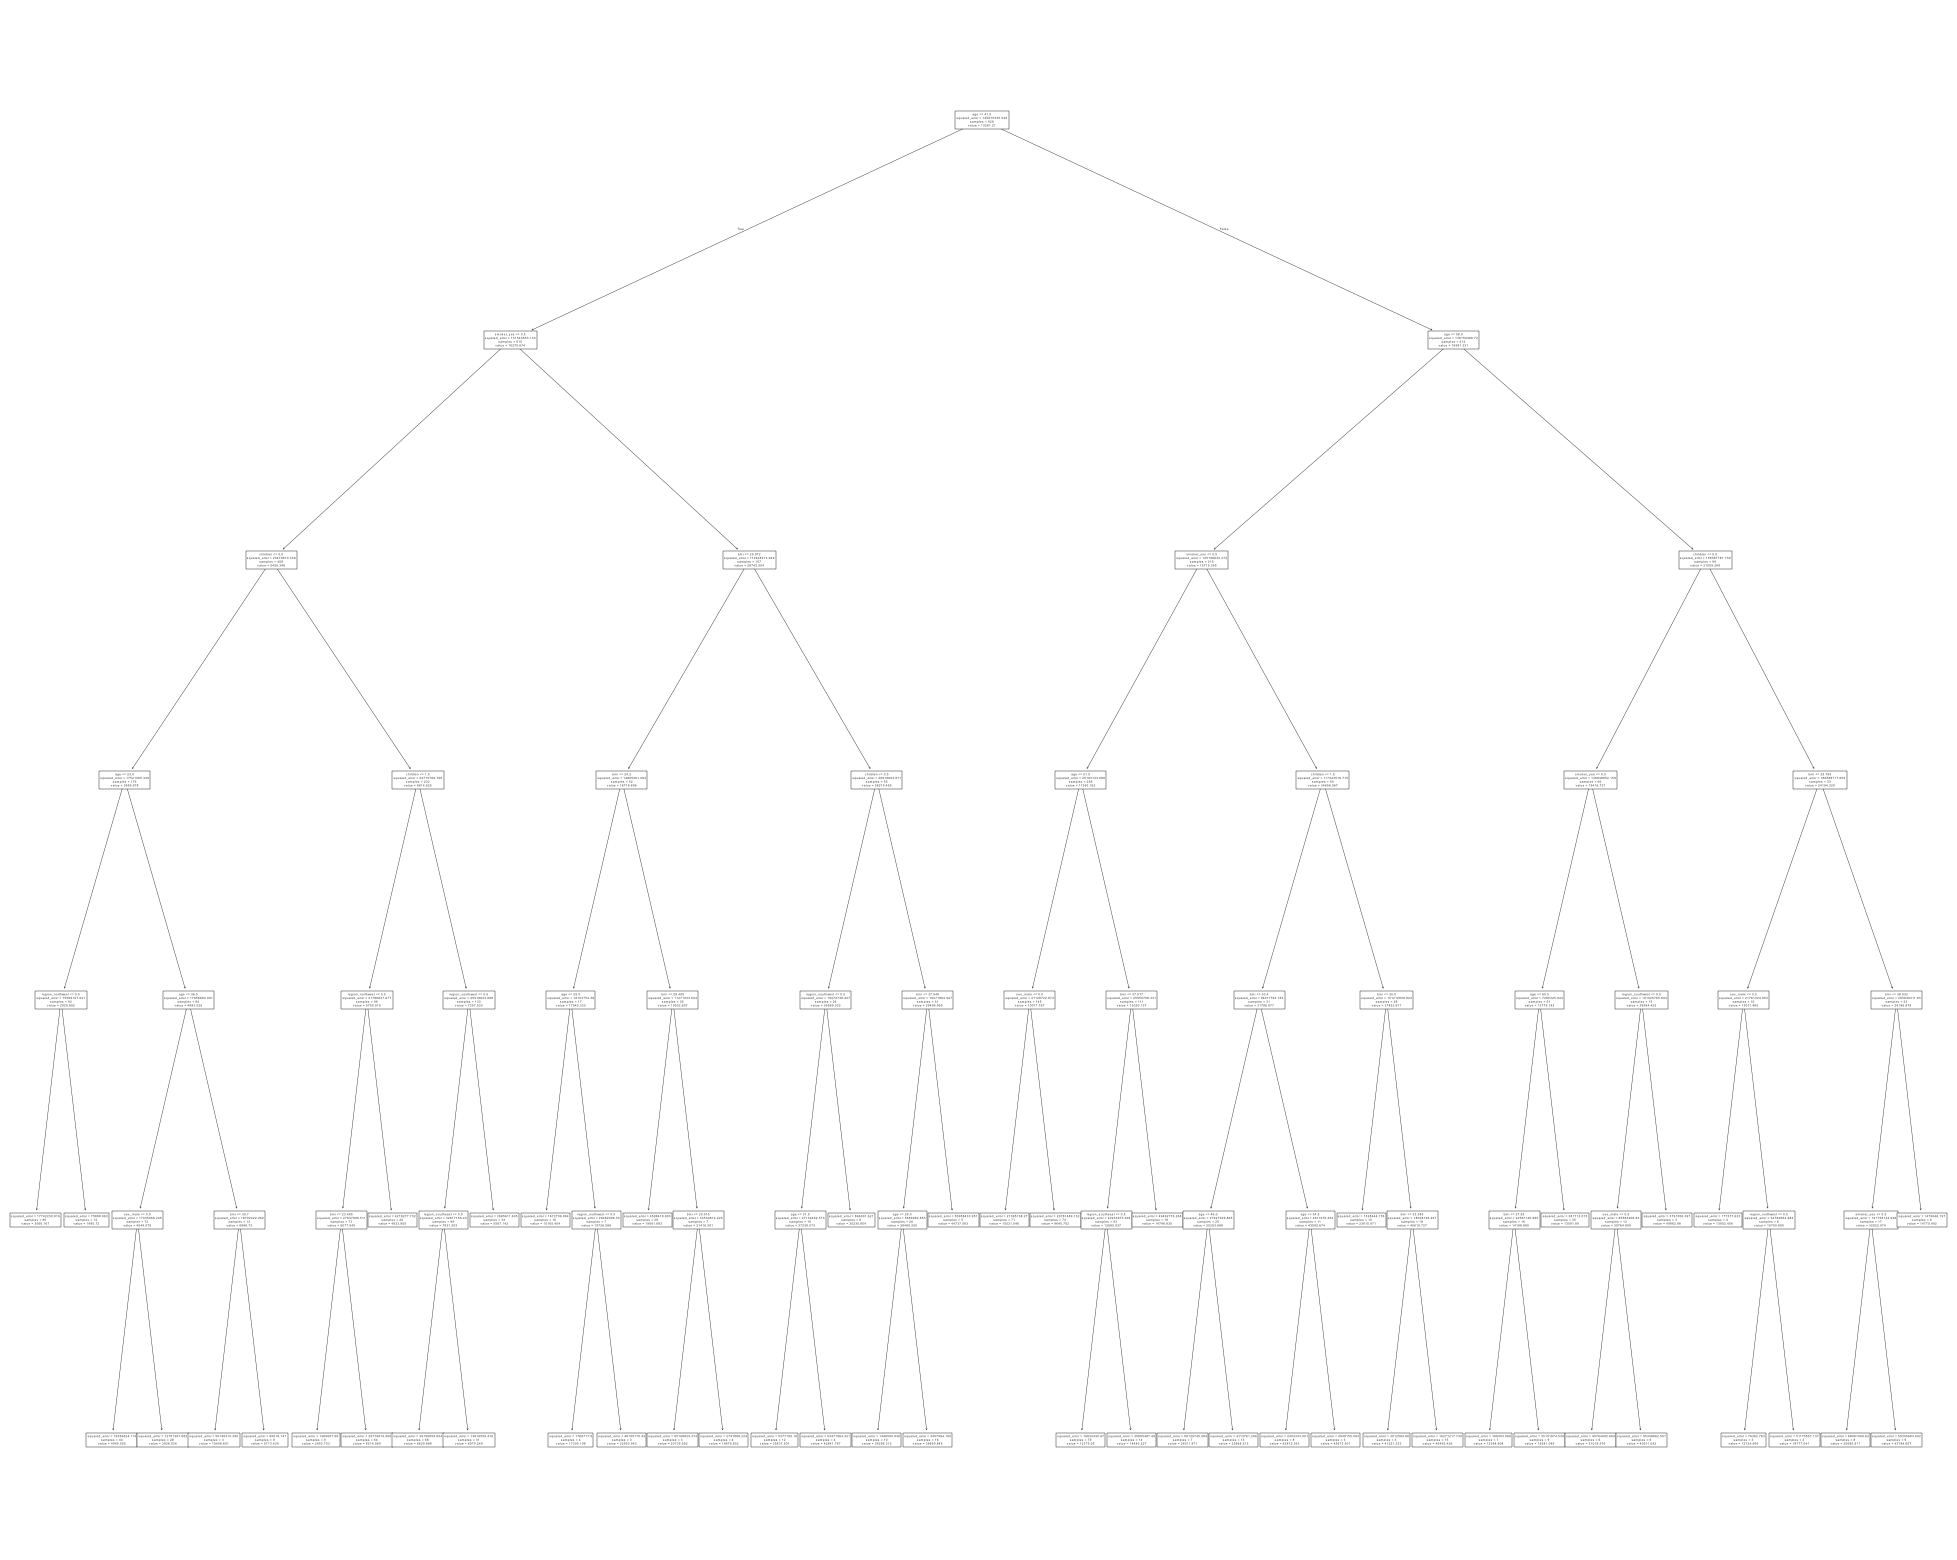

In [160]:
#Best Model (Pruned DT)
Model_5 = DecisionTreeRegressor(max_depth=grid2.best_params_['max_depth'],
                                max_features=grid2.best_params_['max_features'],
                                min_samples_leaf=grid2.best_params_['min_samples_leaf'],
                                splitter=grid2.best_params_['splitter'], 
                                ccp_alpha = best_alpha)
#Fit the decision tree regressor on the train
Model_5.fit(X_train, y_train)

#Plot the Tree
plt.figure(figsize = (25, 20))
plot_tree(Model_5, feature_names = X_train.columns)
plt.show()

In [161]:
y_train_prediction_5 = Model_5.predict(X_train)

print('MAE Train: ', metrics.mean_absolute_error(y_train, y_train_prediction_5))
print('MSE Train: ', metrics.mean_squared_error(y_train, y_train_prediction_5))
print('RMSE Train: ', np.sqrt(metrics.mean_squared_error(y_train, y_train_prediction_5)))
print('MAPE Train: ', metrics.mean_absolute_percentage_error(y_train, y_train_prediction_5))
print('R^2 Train: ', metrics.r2_score(y_train, y_train_prediction_5))

MAE Train:  2562.3036412632437
MSE Train:  19244347.154704303
RMSE Train:  4386.837944887445
MAPE Train:  0.31482736078101653
R^2 Train:  0.867841205848479


In [162]:
y_test_prediction_5 = Model_5.predict(X_test)

Results = pd.concat([Results, 
                             pd.DataFrame({'MSE': metrics.mean_squared_error(y_test, y_test_prediction_5),
                                          'RMSE': np.sqrt(metrics.mean_squared_error(y_test, y_test_prediction_5)),
                                          'MAPE': metrics.mean_absolute_percentage_error(y_test, y_test_prediction_5) * 100,
                                          'MAE' : metrics.mean_absolute_error(y_test, y_test_prediction_5),
                                          'R^2' : metrics.r2_score(y_test, y_test_prediction_5)},                         
                                           index = ['DT - Tunned & Pruned'])])
Results

,MSE,RMSE,MAPE,MAE,R^2
LR - Selected Features,3.570983e+07,5975.769990,41.937878,4137.698443,0.744327
LR - Selected Feature - Box Cox,5.221271e+07,7225.836528,26.387955,3835.371101,0.626170
KNN - Tunned,2.966151e+07,5446.238346,38.428636,3364.491897,0.787631
DT - Tunned & Pruned,2.816717e+07,5307.275253,32.583194,2941.759917,0.798330


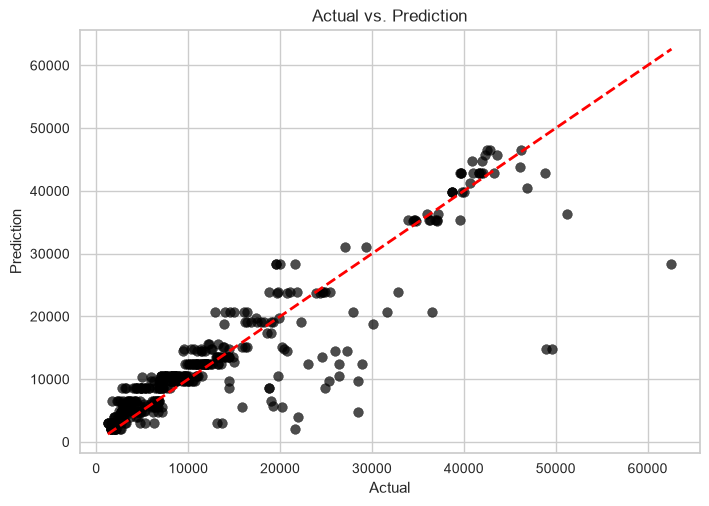

In [163]:
#Plot actual vs. prediction - Test
plt.scatter(y_test, y_test_prediction_5, c = 'black', alpha = 0.7)
plt.xlabel('Actual')
plt.ylabel('Prediction')
plt.title('Actual vs. Prediction')
xp = np.linspace(y_test.min() - 0.2, y_test.max() + 0.2, 100)
plt.plot(xp, xp, c = 'red', linewidth = 2, linestyle='--')
plt.show()

### Random Forest

In [164]:
# Parameter tunning

Parameters={'n_estimators':range(10,100,10),
            'max_depth':range(3,7),
            'max_features':['auto', 'sqrt', 'log2']
}

In [165]:
from sklearn.ensemble import RandomForestRegressor

grid3=GridSearchCV(RandomForestRegressor(),Parameters,cv=10)
grid3.fit(X_train,y_train)
grid3.best_params_

{'max_depth': 6, 'max_features': 'log2', 'n_estimators': 60}

In [166]:
#Build the best Random forest model
Model_6 = RandomForestRegressor(n_estimators=grid3.best_params_['n_estimators'],
                                max_depth=grid3.best_params_['max_depth'],
                                max_features=grid3.best_params_['max_features'],
                                random_state=123)

# Fit the model on train data
Model_6.fit(X_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",60
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'log2'
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",123
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [167]:
y_train_prediction_6 = Model_6.predict(X_train)

print('MAE Train: ', metrics.mean_absolute_error(y_train, y_train_prediction_6))
print('MSE Train: ', metrics.mean_squared_error(y_train, y_train_prediction_6))
print('RMSE Train: ', np.sqrt(metrics.mean_squared_error(y_train, y_train_prediction_6)))
print('MAPE Train: ', metrics.mean_absolute_percentage_error(y_train, y_train_prediction_6))
print('R^2 Train: ', metrics.r2_score(y_train, y_train_prediction_6))

MAE Train:  2600.9475022154274
MSE Train:  16783366.873877984
RMSE Train:  4096.750770290766
MAPE Train:  0.3870832722867109
R^2 Train:  0.884741762865565


In [168]:
# Predict test
y_test_prediction_6 = Model_6.predict(X_test)

Results = pd.concat([Results, 
                     pd.DataFrame({'MSE': metrics.mean_squared_error(y_test, y_test_prediction_6),
                                  'RMSE': np.sqrt(metrics.mean_squared_error(y_test, y_test_prediction_6)),
                                  'MAPE': metrics.mean_absolute_percentage_error(y_test, y_test_prediction_6) * 100,
                                  'MAE' : metrics.mean_absolute_error(y_test, y_test_prediction_6),
                                  'R^2' : metrics.r2_score(y_test, y_test_prediction_6)},                         
                                   index = ['Random Forest - Tuned'])])

Results

,MSE,RMSE,MAPE,MAE,R^2
LR - Selected Features,3.570983e+07,5975.769990,41.937878,4137.698443,0.744327
LR - Selected Feature - Box Cox,5.221271e+07,7225.836528,26.387955,3835.371101,0.626170
KNN - Tunned,2.966151e+07,5446.238346,38.428636,3364.491897,0.787631
DT - Tunned & Pruned,2.816717e+07,5307.275253,32.583194,2941.759917,0.798330
Random Forest - Tuned,2.159170e+07,4646.686584,42.033144,2930.925064,0.845409


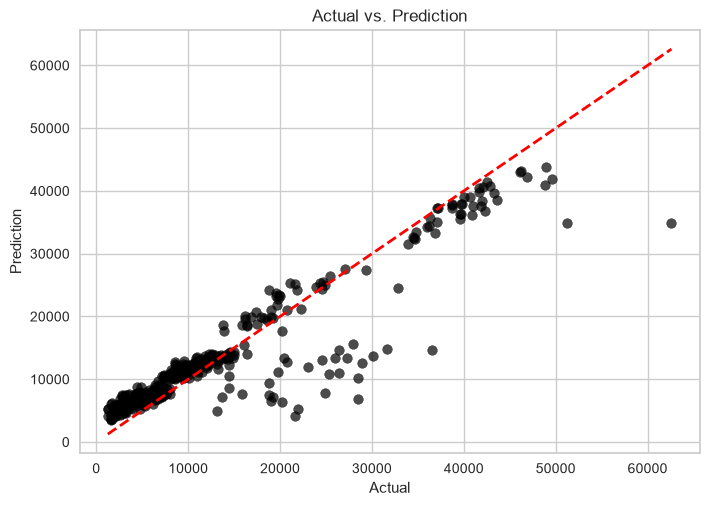

In [169]:
#Plot actual vs. prediction - Test
plt.scatter(y_test, y_test_prediction_6, c = 'black', alpha = 0.7)
plt.xlabel('Actual')
plt.ylabel('Prediction')
plt.title('Actual vs. Prediction')
xp = np.linspace(y_test.min() - 0.2, y_test.max() + 0.2, 100)
plt.plot(xp, xp, c = 'red', linewidth = 2, linestyle='--')
plt.show()